In [ ]:
import pandas
import pandas as pd

df=pd.read_csv('/content/titanic (1) (3).csv')
print(df.shape)
df.head()

(891, 8)


,PassengerId,Pclass,Name,Sex,Age,Ticket,Fare,Survived
0,1,3,"Braund, Mr. Owen Harris",male,22.0,A/5 21171,7.2500,0
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,PC 17599,71.2833,1
2,3,3,"Heikkinen, Miss. Laina",female,26.0,STON/O2. 3101282,7.9250,1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,113803,53.1000,1
4,5,3,"Allen, Mr. William Henry",male,35.0,373450,8.0500,0


In [ ]:
#missing values

df.isnull().sum()

,0
PassengerId,0
Pclass,0
Name,0
Sex,0
Age,177
Ticket,0
Fare,0
Survived,0


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('Survived', axis=1)
Y = df['Survived']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Preprocess the features
# Drop columns that are text-heavy and not easily convertible to numerical values
X_processed = df.drop(columns=['Survived', 'Name', 'Ticket', 'PassengerId'])

# Encode the categorical 'Sex' column into numerical values (0 and 1)
X_processed['Sex'] = X_processed['Sex'].map({'male': 0, 'female': 1})

# Fill missing values in 'Age' with the median age
X_processed['Age'] = X_processed['Age'].fillna(X_processed['Age'].median())

# Define target
Y_processed = df['Survived']

# 2. Re-split the dataset
X_train, X_test, Y_train, Y_test = train_test_split(X_processed, Y_processed, test_size=0.2, random_state=42)

# 3. Initialize and train the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, Y_train)

# 4. Predict and evaluate
Y_pred = model.predict(X_test)

print("Accuracy Score:", accuracy_score(Y_test, Y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(Y_test, Y_pred))
print("\nClassification Report:\n", classification_report(Y_test, Y_pred))

Accuracy Score: 0.8044692737430168

Confusion Matrix:
 [[90 15]
 [20 54]]

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.86      0.84       105
           1       0.78      0.73      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.80      0.80      0.80       179



In [ ]:
from sklearn.neighbors import KNeighborsClassifier

#initialise the knn model
model = KNeighborsClassifier()

#train the knn model
model.fit(X_train, Y_train)


#make prediaction
Y_pred = model.predict(X_test)

print(accuracy_score(Y_test, Y_pred))
print(confusion_matrix(Y_test, Y_pred))
print(classification_report(Y_test, Y_pred))

0.6759776536312849
[[87 18]
 [40 34]]
              precision    recall  f1-score   support

           0       0.69      0.83      0.75       105
           1       0.65      0.46      0.54        74

    accuracy                           0.68       179
   macro avg       0.67      0.64      0.64       179
weighted avg       0.67      0.68      0.66       179



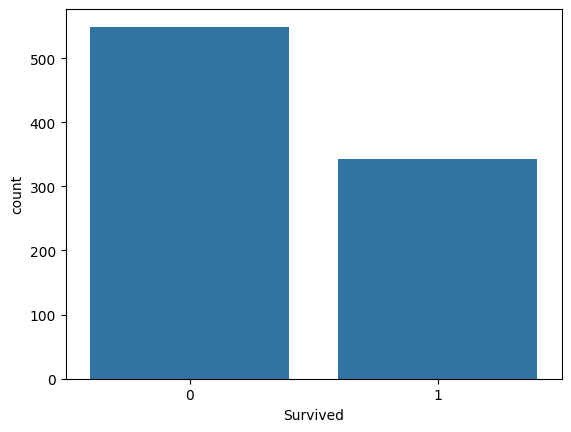

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# count plot on single categorical variable
sns.countplot(x ='Survived', data =df )

# Show the plot
plt.show()

In [ ]:
count_no_sub = len(df[df['Survived']==0])
count_sub = len(df[df['Survived']==1])
pct_of_no_sub = count_no_sub/(count_no_sub+count_sub)
print("percentage of non-survivors is", pct_of_no_sub*100)
pct_of_sub = count_sub/(count_no_sub+count_sub)
print("percentage of survivors is", pct_of_sub*100)

percentage of non-survivors is 61.61616161616161
percentage of survivors is 38.38383838383838


In [ ]:
df.groupby('Survived').mean(numeric_only=True)

,PassengerId,Pclass,Age,Fare
Survived,,,,
0,447.016393,2.531876,30.626179,22.117887
1,444.368421,1.950292,28.343690,48.395408


In [ ]:
# Split Titanic dataset into features (X) and target variable (y)
# Using the preprocessed features we prepared earlier
feature_cols = ['Pclass', 'Sex', 'Age', 'Fare']
X = X_processed[feature_cols]

# Target variable
y = df['Survived']

# Display the variables
print("Features (X) Head:")
print(X.head())
print("\nTarget (y) Head:")
print(y.head())

Features (X) Head:
   Pclass  Sex   Age     Fare
0       3    0  22.0   7.2500
1       1    1  38.0  71.2833
2       3    1  26.0   7.9250
3       1    1  35.0  53.1000
4       3    0  35.0   8.0500

Target (y) Head:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64


In [ ]:
# split X and y into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=16)

In [ ]:
# import the class
from sklearn.linear_model import LogisticRegression

# instantiate the model (using the default parameters)
logreg = LogisticRegression(random_state=16)

# fit the model with data
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)

In [ ]:
print(y_test.value_counts())

Survived
0    137
1     86
Name: count, dtype: int64


In [ ]:
# import the metrics class
from sklearn import metrics

cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[118,  19],
       [ 31,  55]])

Text(0.5, 427.9555555555555, 'Predicted label')

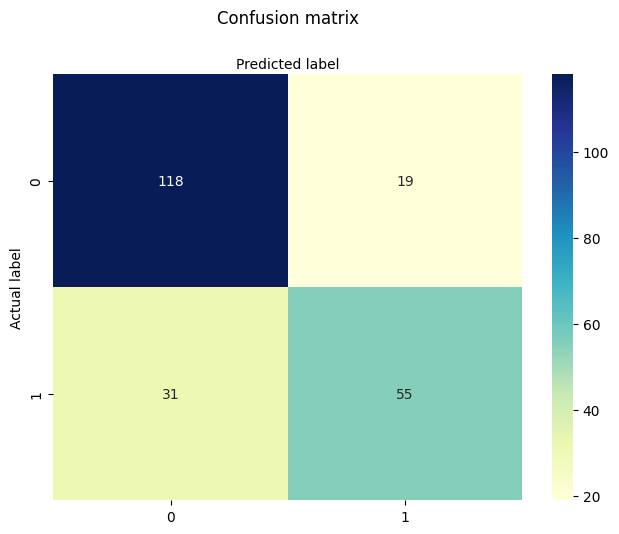

In [ ]:
# import required modules
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')